In [ ]:
# Load basic libraries
import os, json, re, operator, duckdb
from dotenv import load_dotenv
import pandas as pd
from pydantic import BaseModel, Field
from typing import TypedDict, Annotated
from langchain_openai import ChatOpenAI
from langchain_core.messages import AnyMessage, SystemMessage, HumanMessage
from langgraph.graph.message import add_messages
from langchain_core.tools import tool
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode
from IPython.display import Image

# Load and setup environent vriables
load_dotenv(".env")
model_sql = ChatOpenAI(api_key=os.getenv("API_KEY"),model='gpt-4o-mini',temperature=0)

In [ ]:
parientData = pd.read_csv('patient_data.csv')
parientData['last_visit_date'] = pd.to_datetime(parientData['last_visit_date'])
parientData['next_scheduled_visit'] = pd.to_datetime(parientData['next_scheduled_visit'])

parientData['last_visit_date_weekday'] = parientData['last_visit_date'].dt.day_name()
parientData['next_scheduled_visit_weekday'] = parientData['next_scheduled_visit'].dt.day_name()

parientData['age_group'] = pd.cut(parientData["age"],bins=[0, 17, 34, 49, 64, 120],labels=["0-17", "18-34", "35-49", "50-64", "65+"])
parientData.head()

,patient_id,patient_name,age,gender,diagnosis,current_medication,lab_test,lab_value,lab_unit,last_visit_date,...,days_since_last_visit,missed_last_appointment,vitals_bp_systolic,vitals_bp_diastolic,vitals_heart_rate,vitals_spo2,notes,last_visit_date_weekday,next_scheduled_visit_weekday,age_group
0,P0001,Aarav Sharma,68,Male,Type 2 Diabetes,Metformin 500mg,HbA1c,9.9,%,2024-04-24,...,251,No,174,70,95,96,Patient reports good medication adherence.,Wednesday,Saturday,65+
1,P0002,Priya Patel,29,Male,Heart Failure,Furosemide 40mg,BNP,317.6,pg/mL,2024-01-14,...,352,No,174,91,72,97,Patient reports no new symptoms.,Sunday,Wednesday,18-34
2,P0003,Rohan Mehta,45,Male,"Type 2 Diabetes, CKD","Insulin Glargine 10U, Losartan 50mg",HbA1c,11.4,%,2024-08-04,...,149,No,132,86,64,91,Medication dose adjusted this visit.,Sunday,Thursday,35-49
3,P0004,Anjali Singh,34,Female,"COPD, Heart Failure","Tiotropium 18mcg, Furosemide 40mg",FEV1%,33.8,%,2024-01-23,...,343,No,153,70,93,94,Patient reports no new symptoms.,Tuesday,Monday,18-34
4,P0005,Vikram Nair,51,Male,"Hypertension, Heart Failure","Amlodipine 5mg, Furosemide 40mg",BP Systolic,124.9,mmHg,2024-04-26,...,249,No,134,71,82,94,Patient education provided on diet and lifestyle.,Friday,Tuesday,50-64


In [ ]:
def task_1(question: str) -> dict:
    query_con = duckdb.connect(":memory:")
    query_con.register("patients", parientData)
    schema = query_con.execute("DESCRIBE patients").df().to_string(index=False)

    sql_query = model_sql.invoke([
        SystemMessage(content=f"""
            Generate one read-only DuckDB SQL query for the patients table.
            Schema: {schema}
            Rules:
            - Return SQL only, no explanations or Markdown.
            - Start with SELECT or WITH.
            - Use only existing columns and valid DuckDB syntax.
            - Never modify data.
            - `missed_last_appointment` is a timestamp flag, not appointment history.
            - If the question cannot be answered from the schema, return a SELECT query explaining the limitation.
            """),
        HumanMessage(content=question)
    ]).content.strip().removeprefix("```sql").removesuffix("```").strip()

    results = query_con.execute(sql_query).df().to_dict(orient="records")
    query_con.close()
    answer = model_sql.invoke([
        SystemMessage(content="Answer concisely using only the SQL results. Do not invent findings."),
        HumanMessage(content=f"Question: {question}\nResults: {json.dumps(results, default=str)}")
    ]).content

    return {
        "sql_query": sql_query,
        "results": results,
        "answer": answer
    }

In [4]:
# Testing Task 1
response = task_1("which diagnosis has the highest missed appointment percentage?")
print(response["answer"])

The diagnosis with the highest missed appointment percentage is Hypertension, with a percentage of 40.0%.


In [5]:
# Task 2
@tool
def get_patient_data(patient_id: str) -> dict:
    """Retrieve a patient's complete record using their patient ID."""
    print("get_patient_data tool called <<<<<<<<<<<<")
    patient = parientData[parientData["patient_id"] == patient_id]
    if patient.empty:
        return {"error": "Patient not found"}
    return patient.iloc[0].to_dict()

@tool
def get_missed_appointment_patients() -> list:
    """Retrieve patients marked as having missed their last appointment."""
    print("get_missed_appointment_patients tool called <<<<<<<<<<<<")
    patients = parientData[parientData["missed_last_appointment"] == "Yes"]
    return patients.to_dict(orient="records")

@tool
def get_patient_followup_context(patient_id: str) -> dict:
    """Get follow-up relevant details for a patient, including diagnosis,
    medication, lab results, notes, and next scheduled visit."""
    print("get_patient_followup_context tool called <<<<<<<<<<<<")
    patient = get_patient_data.invoke({"patient_id": patient_id})
    if "error" in patient:
        return patient
    fields = [
        "patient_id", "patient_name", "diagnosis",
        "current_medication", "lab_test", "lab_value",
        "lab_unit", "last_visit_date", "next_scheduled_visit",
        "days_since_last_visit", "missed_last_appointment",
        "vitals", "notes"
    ]
    return {key: patient.get(key) for key in fields}

@tool
def filter_patient_data(diagnoses: list[str]) -> dict:
    """Find patient IDs matching any of the requested diagnoses."""
    print("filter_patient_data tool called <<<<<<<<<<<<")
    filtered = parientData[parientData["diagnosis"].str.contains("|".join(diagnoses),case=False,na=False,regex=True)]

    return {"patient_ids": filtered["patient_id"].astype(str).tolist(),"count": len(filtered)}

@tool
def analyze_dataset(question: str) -> dict:
    """this tool is used for EDA with DuckDB SQL query in the database."""
    print("EDA tool called <<<<<<<<<<<<")
    return task_1(question)
tools = [get_patient_data,get_missed_appointment_patients,get_patient_followup_context,analyze_dataset]

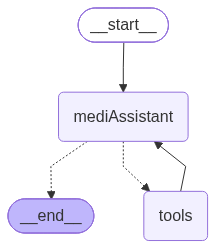

In [6]:
class MedicareState(TypedDict):
    messages: Annotated[list[AnyMessage], add_messages]
llm_with_tools = model_sql.bind_tools(tools)

def mediAssistant(state: MedicareState):
    response = llm_with_tools.invoke([
        SystemMessage(content="""
        you are a agent at MediCare and your task is to do data analysis assistant.

        Decide what to do for each user message:

        - General questions: answer directly without tools.
        - Dataset-wide EDA, counts, statistics, comparisons, trends, and diagnosis analysis across patients: use analyze_dataset.
        - Individual patient queries: use get_patient_data.
        - Patient follow-up questions and suggestions: use get_patient_followup_context and provide practical, data-based guidance.
        - Missed appointment queries: use get_missed_appointment_patients.
        - Patient filtering requests: use filter_patient_data.
        - Follow-up questions: use conversation history to understand context.
        - Ambiguous requests: ask for clarification.
        - Call multiple tools when necessary and summarize their results.

        Response rules:
        - Use tool results as evidence; never invent patient data, diagnoses, or historical appointment counts.
        - Provide specific, actionable follow-up suggestions based on recorded patient data.
        - Do not replace answers with generic disclaimers or refuse routine follow-up assistance.
        - Do not diagnose conditions or prescribe medications.
        - Keep responses concise and structured, with each item on a new line.
        """),
        *state["messages"]
    ])
    return {"messages": [response]}


def route_request(state: MedicareState):
    if state["messages"][-1].tool_calls:
        return "tools"
    return END


graph = StateGraph(MedicareState)

graph.add_node("mediAssistant", mediAssistant)
graph.add_node("tools", ToolNode(tools))

graph.add_edge(START, "mediAssistant")
graph.add_conditional_edges("mediAssistant",route_request,{"tools": "tools", END: END})
graph.add_edge("tools", "mediAssistant")

workflow = graph.compile()
Image(workflow.get_graph().draw_mermaid_png())

In [ ]:
chat_history = []

def chat(user_message: str):
    global chat_history

    chat_history.append(HumanMessage(content=user_message))

    result = workflow.invoke({"messages": chat_history})

    chat_history = result["messages"]

    return chat_history[-1].content

In [8]:
# Testing Task 1 / task 2/ task 3
print(chat("Analyze the dataset, tell me the basic information like on which day of the week a customer is more likly to miss an appointment?"))

EDA tool called <<<<<<<<<<<<
Patients are more likely to miss an appointment on **Friday**, with a total of **4 missed appointments** recorded on that day.


In [9]:
print(chat("which diagnosis has the highest missed appointment percentage?"))

EDA tool called <<<<<<<<<<<<
The diagnosis with the highest percentage of missed appointments is **Hypertension**, with a missed appointment percentage of **40.0%**.


In [10]:
# getting detials of a patient from task 4 - Single Patient Analysis 
print(chat("Now show me patient P0003's details."))

get_patient_data tool called <<<<<<<<<<<<
Here are the details for patient **Rohan Mehta (P0003)**:

- **Age:** 45
- **Gender:** Male
- **Diagnosis:** Type 2 Diabetes, CKD
- **Current Medication:** 
  - Insulin Glargine 10U
  - Losartan 50mg
- **Lab Test:** HbA1c
- **Lab Value:** 11.4% 
- **Last Visit Date:** August 4, 2024 (Sunday)
- **Next Scheduled Visit:** October 3, 2024 (Thursday)
- **Days Since Last Visit:** 149
- **Missed Last Appointment:** No
- **Vitals:**
  - Blood Pressure: 132/86 mmHg
  - Heart Rate: 64 bpm
  - SpO2: 91%
- **Notes:** Medication dose adjusted this visit.


In [11]:
print(chat("What follow-up would you suggest for this patient?"))

get_patient_followup_context tool called <<<<<<<<<<<<
get_patient_data tool called <<<<<<<<<<<<
For patient **Rohan Mehta**, here are the suggested follow-up actions:

- **Monitor HbA1c Levels:** The current HbA1c level is **11.4%**, which indicates poor glycemic control. Regular monitoring and adjustments to the diabetes management plan may be necessary.
  
- **Medication Review:** Since the medication dose was adjusted during the last visit, ensure that Rohan is adhering to the new regimen of **Insulin Glargine 10U** and **Losartan 50mg**. 

- **Next Scheduled Visit:** Encourage Rohan to attend the next scheduled visit on **October 3, 2024**, to reassess his condition and make any necessary adjustments.

- **Lifestyle Modifications:** Discuss dietary changes, physical activity, and weight management strategies to help improve diabetes control.

- **Kidney Function Monitoring:** Given the diagnosis of CKD, regular monitoring of kidney function tests should be emphasized.

- **Patient 

In [12]:
print(chat("give patient id where Missed Last Appointment is yes"))

get_missed_appointment_patients tool called <<<<<<<<<<<<
Here are the patient IDs where the last appointment was missed:

1. **P0018** - Lakshmi Menon
2. **P0031** - Harish Bajaj
3. **P0036** - Vandana Srivastava
4. **P0041** - Tarun Mukherjee
5. **P0043** - Gaurav Dey
6. **P0058** - Hina Akhtar
7. **P0062** - Mary Joseph
8. **P0063** - John Fernandez
9. **P0066** - Angela Pereira
10. **P0069** - Victor Lobo
11. **P0070** - Teresa Dias
12. **P0076** - Parmjit Hundal
13. **P0081** - Nandini Rao
14. **P0098** - Mrinal Basu
15. **P0099** - Paramita Chatterjee


In [13]:
print(chat("Now show me patient P0018's details."))

get_patient_data tool called <<<<<<<<<<<<
Here are the details for patient **Lakshmi Menon (P0018)**:

- **Age:** 36
- **Gender:** Female
- **Diagnosis:** Heart Failure
- **Current Medication:** Furosemide 40mg
- **Lab Test:** BNP
- **Lab Value:** 952.3 pg/mL
- **Last Visit Date:** July 27, 2024 (Saturday)
- **Next Scheduled Visit:** September 10, 2024 (Tuesday)
- **Days Since Last Visit:** 157
- **Missed Last Appointment:** Yes
- **Vitals:**
  - Blood Pressure: 160/87 mmHg
  - Heart Rate: 85 bpm
  - SpO2: 96%
- **Notes:** Patient education provided on diet and lifestyle.


In [14]:
print(chat("What follow-up would you suggest for this patient?"))

get_patient_followup_context tool called <<<<<<<<<<<<
get_patient_data tool called <<<<<<<<<<<<
For patient **Lakshmi Menon**, here are the suggested follow-up actions:

- **Monitor BNP Levels:** The current BNP level is **952.3 pg/mL**, which indicates heart failure. Regular monitoring is essential to assess heart function and fluid status.

- **Medication Adherence:** Ensure that Lakshmi is taking her medication, **Furosemide 40mg**, as prescribed. Discuss any side effects or concerns she may have regarding her medication.

- **Next Scheduled Visit:** Encourage her to attend the next scheduled visit on **September 10, 2024**, to reassess her condition and adjust treatment if necessary.

- **Lifestyle Modifications:** Reinforce the importance of dietary changes, such as sodium restriction, and encourage regular physical activity as tolerated.

- **Patient Education:** Continue providing education on recognizing signs of worsening heart failure, such as increased shortness of breath, s

In [15]:
print(chat("prepare a small follow-up care message to be sent to this patient mentioning next scheduled visit"))

Here's a follow-up care message for patient **Lakshmi Menon**:

---

**Dear Lakshmi Menon,**

We hope this message finds you well. We wanted to remind you of your next scheduled visit on **September 10, 2024**. It is important to attend this appointment to monitor your heart health and discuss any concerns you may have.

Please remember to take your medication, **Furosemide 40mg**, as prescribed, and continue following the dietary recommendations provided during your last visit.

If you have any questions or need assistance before your appointment, feel free to reach out.

Take care, and we look forward to seeing you soon!

Best regards,  
[Your Healthcare Team]

--- 

Feel free to customize the message further if needed!


In [16]:
print(chat("find all patient with any of these Type 2 Diabetes, Hypertension, Heart Failure, COPD, and Anemia"))

EDA tool called <<<<<<<<<<<<
Here are the patients with any of the following diagnoses: Type 2 Diabetes, Hypertension, Heart Failure, COPD, and Anemia:

1. **P0001** - Aarav Sharma, Age: 68, Gender: Male, Diagnosis: Type 2 Diabetes
2. **P0002** - Priya Patel, Age: 29, Gender: Male, Diagnosis: Heart Failure
3. **P0007** - Karan Gupta, Age: 57, Gender: Female, Diagnosis: COPD
4. **P0008** - Deepa Krishnan, Age: 45, Gender: Male, Diagnosis: Heart Failure
5. **P0014** - Pooja Desai, Age: 43, Gender: Male, Diagnosis: Heart Failure
6. **P0016** - Meera Nambiar, Age: 61, Gender: Female, Diagnosis: Hypertension
7. **P0017** - Sanjay Pillai, Age: 73, Gender: Male, Diagnosis: Heart Failure
8. **P0018** - Lakshmi Menon, Age: 36, Gender: Female, Diagnosis: Heart Failure
9. **P0021** - Mohammed Khan, Age: 69, Gender: Male, Diagnosis: Hypertension
10. **P0022** - Fatima Ansari, Age: 52, Gender: Male, Diagnosis: Anemia
11. **P0023** - Arjun Tiwari, Age: 40, Gender: Female, Diagnosis: Heart Failure
12